# Evaluación Formativa 2. Práctica de modelamiento predictivo
## Framingham Heart Study: riesgo de enfermedad coronaria a 10 años

MCDI501 · Grupo 3 · Integrantes: Felipe Díaz Toro, Pablo Ríos Passteni, Guillermo Subiabre Chacón, Ninoska Yévenes Hernández


## Propósito de esta formativa

Esta formativa es la **práctica previa a la Sumativa 3**: ensayamos el flujo completo de modelamiento predictivo con un modelo simple, para recibir retroalimentación antes del proyecto final. Es una versión simplificada de S3: **un** modelo logístico, imputación simple de faltantes y sin bootstrap de coeficientes.

### El problema

La enfermedad coronaria (CHD) es una de las principales causas de enfermedad cardiovascular. Con el **Framingham Heart Study** (4.238 participantes, 16 variables) queremos **anticipar quién desarrollará CHD en los 10 años siguientes** (`TenYearCHD`: 1 = sí, 0 = no), a partir de variables medidas al inicio del seguimiento (edad, sexo, presión arterial, glucosa, tabaquismo, etc.). Solo el 15,2 % de los participantes desarrolla CHD, así que las clases están **desbalanceadas**, y eso condiciona cómo se interpretan las métricas.

## 0. Configuración y datos

La primera celda importa las librerías, **ubica el repositorio y carga el dataset** `data/raw/framingham.csv`. Antes de usarlo verifica su huella SHA-256 y su forma (4.238 × 16), para asegurar que es exactamente la misma copia de S1 y S2 y que los resultados sean comparables. La segunda celda fija la semilla (`SEED = 42`, para reproducibilidad), define la variable objetivo y el estilo de las figuras, e imprime la prevalencia de CHD.

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_curve, auc)

# Ubicar el repositorio sin depender de rutas relativas
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "requirements.txt").exists() and (p / "redaccion").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Abra el notebook dentro del repositorio del proyecto.")

# Copia versionada del dataset: se verifica para que los resultados sean los de S1 y S2
CSV = ROOT / "data/raw/framingham.csv"
SHA_ESPERADO = "40921748dbdf6587045b9822414199a1ae3349358b63b975ab2208aa3cccc45b"
FORMA_ESPERADA = (4238, 16)
sha = hashlib.sha256(CSV.read_bytes()).hexdigest()
df = pd.read_csv(CSV)
if sha != SHA_ESPERADO or df.shape != FORMA_ESPERADA:
    raise ValueError("data/raw/framingham.csv no es la copia del proyecto. "
                     "Restáurela con: git checkout -- data/raw/framingham.csv")
print(f"Dataset verificado: {df.shape[0]:,} filas x {df.shape[1]} columnas".replace(",", "."))
print("SHA-256:", sha)

SEED = 42
np.random.seed(SEED)
TARGET = "TenYearCHD"

# Misma paleta y estilo que S1 y S2
NAVY, RED, GREY, BG, OCHRE = "#0d2741", "#ae0000", "#8c8578", "#f6f1ea", "#c0852f"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.facecolor": BG,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": "#ddd5c6", "axes.axisbelow": True,
})

print(f"Prevalencia de {TARGET}: {df[TARGET].mean():.1%} ({int(df[TARGET].sum())} de {len(df):,} casos)".replace(",", "."))

Dataset verificado: 4.238 filas x 16 columnas
SHA-256: 40921748dbdf6587045b9822414199a1ae3349358b63b975ab2208aa3cccc45b
Prevalencia de TenYearCHD: 15.2% (644 de 4.238 casos)


## 1. Preparación de datos para modelamiento (21 pts)
### 1.1 Hallazgos de S1 y S2
El punto de partida no es el dato crudo, sino lo aprendido en S1 (exploración e inferencia) y S2 (validación con remuestreo). La tabla compara la correlación de cada variable candidata con `TenYearCHD` (S1) y, cuando existe, su IC bootstrap al 95 % de S2.

In [2]:
# Correlaciones de Pearson con TenYearCHD (casos disponibles de cada par), como en S1
candidatas = ["age", "male", "sysBP", "cigsPerDay", "glucose", "totChol", "BMI", "prevalentHyp", "diabetes"]
corr_s1 = df[candidatas + [TARGET]].corr()[TARGET].drop(TARGET)

# Validación bootstrap de S2 (IC percentil 95 %, 10.000 remuestras); solo se validaron estas
S2_IC = {"age": [0.197, 0.254], "sysBP": [0.183, 0.250]}

tabla = pd.DataFrame({
    "r con CHD (S1)": corr_s1.round(3),
    "IC bootstrap (S2)": [str(S2_IC[v]) if v in S2_IC else "no validada en S2" for v in corr_s1.index],
}).sort_values("r con CHD (S1)", ascending=False)
tabla

,r con CHD (S1),IC bootstrap (S2)
age,0.225,"[0.197, 0.254]"
sysBP,0.216,"[0.183, 0.25]"
prevalentHyp,0.178,no validada en S2
glucose,0.126,no validada en S2
diabetes,0.097,no validada en S2
male,0.088,no validada en S2
totChol,0.082,no validada en S2
BMI,0.075,no validada en S2
cigsPerDay,0.058,no validada en S2


**Lectura.** Las variables más asociadas con CHD son la edad (r = 0,225) y la presión sistólica (r = 0,216), y S2 confirmó que ambas son estables: sus IC bootstrap [0,197; 0,254] y [0,183; 0,250] son estrechos y no incluyen el cero. Les siguen hipertensión prevalente (0,178), glucosa (0,126), diabetes (0,097) y sexo masculino (0,088); cigarrillos por día (0,058) es la más baja. Todas las correlaciones son modestas (la máxima es 0,23), lo esperable en un fenómeno multifactorial a 10 años: ninguna variable predice bien por sí sola, por eso se modelan en conjunto. Además, S2 solo validó con bootstrap cinco correlaciones; las demás candidatas no pasaron por esa validación y se declara explícitamente en la tabla. Para el tabaquismo, S2 mostró que fumador actual–CHD (r = 0,019) no se distingue de cero.

**Faltantes y valores extremos (S1).** Se revisan los datos faltantes y los valores extremos que S1 ya había caracterizado, porque condicionan el tratamiento de la sección 1.2.

In [3]:
falt = df.isna().sum()
falt = pd.DataFrame({"faltantes": falt, "%": (100 * falt / len(df)).round(1)}).query("faltantes > 0")
display(falt)

# Valores extremos por la regla de Tukey en las variables que usaremos
def pct_tukey(x):
    x = x.dropna(); q1, q3 = x.quantile([.25, .75]); i = q3 - q1
    return 100 * ((x < q1 - 1.5 * i) | (x > q3 + 1.5 * i)).mean()
print({v: round(pct_tukey(df[v]), 1) for v in ["sysBP", "glucose", "cigsPerDay", "age"]})

,faltantes,%
education,105,2.5
cigsPerDay,29,0.7
BPMeds,53,1.3
totChol,50,1.2
BMI,19,0.4
heartRate,1,0.0
glucose,388,9.2


{'sysBP': np.float64(3.0), 'glucose': np.float64(4.9), 'cigsPerDay': np.float64(0.3), 'age': np.float64(0.0)}


**Lectura.** Hay faltantes en siete variables, ninguna sobre el 10 %: la glucosa concentra la mayor parte (388 casos, 9,2 %), seguida de educación (105, 2,5 %); los 29 de cigarrillos por día (0,7 %) son todos fumadores actuales (S1). Entre los predictores que usaremos, solo glucosa y cigarrillos por día tienen faltantes. La regla de Tukey marca 3,0 % de valores extremos en la presión sistólica, 4,9 % en la glucosa, 0,3 % en cigarrillos por día y 0 % en la edad. S1 mostró que son plausibles (los registros de glucosa de 200 mg/dL o más corresponden a personas diabéticas), por eso no se eliminan: se acota la cola de la glucosa en la sección 1.2, como recomendó S2.

### 1.2 Tratamiento de faltantes, partición y estandarización
Estrategia simple, en este orden: (1) partición 70/30 estratificada por `TenYearCHD`, (2) tope de la glucosa, (3) imputación con medianas y (4) estandarización. Todo se calcula con el conjunto de entrenamiento y se aplica al de prueba.

In [4]:
predictores = ["age", "sysBP", "male", "cigsPerDay", "glucose"]
X = df[predictores].copy()
y = df[TARGET]

# 1) Partición 70/30 estratificada ANTES de imputar o estandarizar (evita fuga de información al test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y)
print(f"Train: {len(X_train):,} | Test: {len(X_test):,}".replace(",", "."))
print("Prevalencia train:", round(y_train.mean(), 4), "| test:", round(y_test.mean(), 4))

# 2) Glucosa: acotar al P99 calculado SOLO en train (S2 recomendó ~175 mg/dL)
tope = X_train["glucose"].quantile(0.99)
X_train["glucose"] = X_train["glucose"].clip(upper=tope)
X_test["glucose"] = X_test["glucose"].clip(upper=tope)
print(f"Tope de glucosa (P99 de train): {tope:.1f} mg/dL")

# 3) Faltantes: mediana calculada en train y aplicada a train y test
# cigsPerDay: los 29 faltantes son fumadores actuales (S1); la mediana general es 0, así que se usa la de los fumadores de train
fum_train = df.loc[X_train.index, "currentSmoker"] == 1
medianas = X_train.median()
medianas["cigsPerDay"] = X_train.loc[fum_train, "cigsPerDay"].median()
print(f"Mediana de cigarrillos por día (fumadores, train): {medianas['cigsPerDay']:.0f}")
X_train = X_train.fillna(medianas)
X_test = X_test.fillna(medianas)
print("Faltantes restantes (train, test):", int(X_train.isna().sum().sum()), int(X_test.isna().sum().sum()))

# 4) Estandarizar con media y desviación del train
scaler = StandardScaler().fit(X_train)
X_train_sc = pd.DataFrame(scaler.transform(X_train), columns=predictores, index=X_train.index)
X_test_sc = pd.DataFrame(scaler.transform(X_test), columns=predictores, index=X_test.index)
X_train_sc.describe().round(2).loc[["mean", "std"]]

Train: 2.966 | Test: 1.272
Prevalencia train: 0.1521 | test: 0.1517
Tope de glucosa (P99 de train): 187.1 mg/dL
Mediana de cigarrillos por día (fumadores, train): 20
Faltantes restantes (train, test): 0 0


,age,sysBP,male,cigsPerDay,glucose
mean,-0.0,0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0


**Lectura.** La partición deja 2.966 participantes en train y 1.272 en test con la misma prevalencia de CHD (15,21 % y 15,17 %): la estratificación evita que el azar deje pocos casos en alguno de los conjuntos. Dividimos **antes** de imputar y estandarizar para evitar fuga de información: las medianas, el tope y la escala salen solo del train y se aplican al test, que representa datos nuevos. La glucosa se acota al percentil 99 de train (187,1 mg/dL; en todo el dataset es 175, según S2): el valor difiere porque se calcula con el 70 % de los datos y esa cola es muy rala. El tope limita el peso de los casos extremos sin eliminarlos. Se imputa con la mediana porque es robusta a la asimetría de la glucosa y conserva los 4.238 casos; su costo es reducir artificialmente la variabilidad, aceptable en una formativa (S3 comparará con imputación por regresión). En cigarrillos por día se usa la mediana de los **fumadores** de train, porque los 29 faltantes son fumadores actuales y la mediana general es 0, que los habría tratado como no fumadores. Tras estandarizar, los predictores tienen media 0 y desviación 1 en train, de modo que los coeficientes se interpretarán por desviación estándar y serán comparables entre sí.

## 2. Modelo de regresión logística (30 pts)
### 2.1 Selección de variables (3 a 5)
Se seleccionan **cinco predictores** con un criterio doble: que la asociación con CHD aparezca en S1 y, cuando S2 la validó, que resista el remuestreo.

| Variable | r con CHD (S1) | IC bootstrap (S2) | Justificación |
|---|---|---|---|
| Edad | 0,225 | [0,197; 0,254] | Factor de riesgo principal; estable en S2. |
| Presión sistólica | 0,216 | [0,183; 0,250] | Segunda asociación más fuerte; estable en S2. Representa a todo el bloque de presión arterial. |
| Glucosa | 0,126 | no validada | Marcador metabólico; S2 recomendó acotar su cola, lo que se hace en 1.2. |
| Sexo masculino | 0,088 | no validada | Mayor riesgo cardiovascular en hombres; casi no se correlaciona con los demás predictores. |
| Cigarrillos por día | 0,058 | no validada | Captura el tabaquismo: S2 no distingue de cero la correlación marginal, pero eso no permite descartar su aporte en un modelo multivariable. |

**Variables excluidas.** La presión diastólica (r = 0,78 con la sistólica) y la hipertensión prevalente (r = 0,70) forman un bloque colineal con la sistólica (S2), así que entra solo una; diabetes se solapa con la glucosa (r = 0,62, S2); colesterol total e IMC tienen asociaciones débiles (0,082 y 0,075). Con unos 451 casos de CHD en train, hay cerca de 90 por predictor, margen amplio para ajustar cinco variables.

### 2.2 Ajuste e interpretación
Se ajusta el modelo logístico con los cinco predictores estandarizados y se calculan los odds ratios (exponencial de cada coeficiente), su p-valor y su significancia al 5 %.

In [5]:
X_train_const = sm.add_constant(X_train_sc)
X_test_const = sm.add_constant(X_test_sc)

modelo = sm.Logit(y_train, X_train_const).fit()
print(modelo.summary())

odds_ratios = np.exp(modelo.params)
interpretacion = pd.DataFrame({
    "Coeficiente": modelo.params,
    "Odds Ratio": odds_ratios,
    "p-valor": modelo.pvalues,
    "Significativo (α=0.05)": modelo.pvalues < 0.05,
}).round(4)
interpretacion

Optimization terminated successfully.
         Current function value: 0.376462
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:             TenYearCHD   No. Observations:                 2966
Model:                          Logit   Df Residuals:                     2960
Method:                           MLE   Df Model:                            5
Date:                Tue, 20 Oct 2026   Pseudo R-squ.:                  0.1168
Time:                        16:31:08   Log-Likelihood:                -1116.6
converged:                       True   LL-Null:                       -1264.3
Covariance Type:            nonrobust   LLR p-value:                 9.750e-62
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.9913      0.063    -31.635      0.000      -2.115      -1.868
age            0.6079      0.

,Coeficiente,Odds Ratio,p-valor,Significativo (α=0.05)
const,-1.9913,0.1365,0.0000,True
age,0.6079,1.8366,0.0000,True
sysBP,0.4037,1.4973,0.0000,True
male,0.2014,1.2231,0.0005,True
cigsPerDay,0.2910,1.3378,0.0000,True
glucose,0.1538,1.1662,0.0008,True


**Lectura.** Los cinco predictores son significativos al 5 % (p ≤ 0,0008 en todos los casos): ninguno queda fuera del modelo. Como están estandarizados, cada odds ratio se lee "por cada desviación estándar de aumento en la variable, manteniendo las demás constantes" (para `male`, variable binaria, el OR aproxima el efecto de ser hombre frente a mujer, dado que su desviación estándar cubre buena parte del rango 0-1). La edad tiene el mayor efecto (OR = 1,84): es la variable que más multiplica los odds de CHD, coherente con ser la más correlacionada en S1. Le sigue la presión sistólica (OR = 1,50). Cigarrillos por día (OR = 1,34) y glucosa (OR = 1,17) también aumentan el riesgo: el tabaquismo sí aporta en el modelo multivariable, aunque S2 no distinguiera de cero su correlación marginal. El sexo masculino (OR = 1,22) también es significativo: ser hombre se asocia a mayores odds de CHD, consistente con la literatura cardiovascular. El modelo mejora de forma clara sobre el nulo (LLR p < 0,001) y explica una fracción moderada de la variación (pseudo R² = 0,117), razonable para un fenómeno multifactorial a 10 años.

### 2.3 Diagnóstico: VIF
Se calcula el factor de inflación de varianza (VIF) de cada predictor sobre el conjunto de entrenamiento estandarizado, para descartar multicolinealidad relevante entre los cinco predictores (umbral de referencia: VIF > 5).

In [6]:
X_vif = sm.add_constant(X_train_sc)
vif = pd.DataFrame({
    "Variable": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])],
}).round(2)
vif

,Variable,VIF
0,const,1.00
1,age,1.23
2,sysBP,1.20
3,male,1.12
4,cigsPerDay,1.17
5,glucose,1.03


**Lectura.** Los VIF de los cinco predictores están entre 1,03 y 1,23, muy por debajo del umbral de 5: no hay evidencia de multicolinealidad relevante entre ellos (la fila `const` se ignora, su VIF alto es normal y no indica un problema). Esto es consistente con la selección de variables de 2.1, que ya excluyó los pares fuertemente correlacionados (diastólica e hipertensión prevalente con sistólica; diabetes con glucosa) precisamente para evitar este problema. Si hubiera aparecido un VIF > 5, la solución habría sido eliminar una de las variables del par colineal (ya aplicado aquí en 2.1) o, alternativamente, combinarlas en un índice compuesto o usar regularización (Ridge) para estabilizar los coeficientes.

## 3. Evaluación de desempeño predictivo (30 pts)
### 3.1 Matriz de confusión y métricas
Con el modelo ajustado en 2.2 se predice la probabilidad de CHD de cada participante del conjunto de prueba y se clasifica como "CHD" si supera el umbral por defecto de 0,5. Se construye la matriz de confusión y se calculan accuracy, precision, recall y F1-score de la clase de interés (CHD = 1).

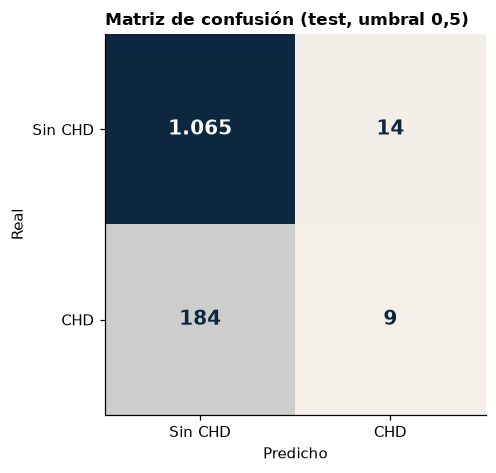

Verdaderos negativos (TN): 1.065
Falsos positivos     (FP): 14
Falsos negativos     (FN): 184
Verdaderos positivos (TP): 9

              Métrica  Valor
             Accuracy 0.8443
            Precision 0.3913
Recall (sensibilidad) 0.0466
             F1-score 0.0833

Accuracy del clasificador trivial (siempre 'sin CHD'): 0.8483


In [7]:
FIGURAS = ROOT / "redaccion/formativa-2-modelamiento-predictivo/figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

# Predicciones sobre el conjunto de prueba con el umbral por defecto (0,5)
y_prob = modelo.predict(X_test_const)
y_pred = (y_prob >= 0.5).astype(int)

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

# Matriz de confusión (filas = real, columnas = predicho)
from matplotlib.colors import LinearSegmentedColormap
fig, ax = plt.subplots(figsize=(5.2, 4.4))
ax.imshow(cm, cmap=LinearSegmentedColormap.from_list("bg_navy", [BG, NAVY]), vmin=0, vmax=cm.max())
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, f"{v:,}".replace(",", "."), ha="center", va="center", fontsize=13,
            fontweight="bold", color="white" if v / cm.max() > 0.5 else NAVY)
ax.set_xticks([0, 1]); ax.set_xticklabels(["Sin CHD", "CHD"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["Sin CHD", "CHD"])
ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
ax.set_title("Matriz de confusión (test, umbral 0,5)")
ax.grid(False)
plt.tight_layout()
plt.savefig(FIGURAS / "fig_confusion.png", bbox_inches="tight")
plt.show()

print(f"Verdaderos negativos (TN): {tn:,}".replace(",", "."))
print(f"Falsos positivos     (FP): {fp:,}".replace(",", "."))
print(f"Falsos negativos     (FN): {fn:,}".replace(",", "."))
print(f"Verdaderos positivos (TP): {tp:,}".replace(",", "."))

# Métricas de la clase de interés (CHD = 1)
metricas = pd.DataFrame({
    "Métrica": ["Accuracy", "Precision", "Recall (sensibilidad)", "F1-score"],
    "Valor": [accuracy_score(y_test, y_pred), precision_score(y_test, y_pred, zero_division=0),
              recall_score(y_test, y_pred), f1_score(y_test, y_pred)],
}).round(4)
print()
print(metricas.to_string(index=False))

# Referencia: un clasificador trivial que predijera "sin CHD" para todos
print(f"\nAccuracy del clasificador trivial (siempre 'sin CHD'): {1 - y_test.mean():.4f}")

**Lectura.** De los 1.272 participantes del conjunto de prueba, 193 desarrollan CHD (15,2 %). Con el umbral de 0,5 el modelo marca como CHD a solo 23 personas (9 verdaderos positivos y 14 falsos positivos) y deja pasar a 184 de los 193 casos reales (falsos negativos).

- **Accuracy (84,4 %):** parece alta, pero es engañosa. Un clasificador trivial que dijera "sin CHD" para todos alcanzaría 84,8 %, algo más: el modelo no supera al trivial en accuracy porque casi no predice la clase minoritaria.
- **Precision (39,1 %):** cuando el modelo marca a alguien como CHD acierta en 9 de 23 casos, más del doble de la prevalencia (15,2 %), pero lo hace muy pocas veces.
- **Recall (4,7 %):** detecta solo 9 de los 193 casos reales. En salud, no detectar a quien desarrollará CHD (falso negativo) suele ser el error más costoso, por lo que el recall es la métrica crítica y aquí es muy bajo.
- **F1-score (0,083):** la media armónica refleja ese desequilibrio entre una precision moderada y un recall casi nulo.

**Por qué ocurre.** Con una prevalencia de 15,2 %, la probabilidad que predice el modelo casi nunca supera 0,5, ni siquiera en las personas de mayor riesgo; el umbral por defecto no es adecuado para un problema desbalanceado. Esto no significa que el modelo ordene mal: su capacidad para ordenar a los participantes por riesgo se evalúa con el AUC en 3.2, que no depende del umbral. Para S3 conviene ponderar las clases y elegir el umbral con criterio (por ejemplo, cerca de la prevalencia), en vez de usar 0,5 por defecto.

### 3.2 Curva ROC y AUC
Se calcula la probabilidad predicha en test con el modelo ajustado en 2.2, la curva ROC y el AUC, y se interpreta según la escala de referencia (0,5 azar; 0,6-0,7 pobre; 0,7-0,8 aceptable; 0,8-0,9 bueno; >0,9 excelente).

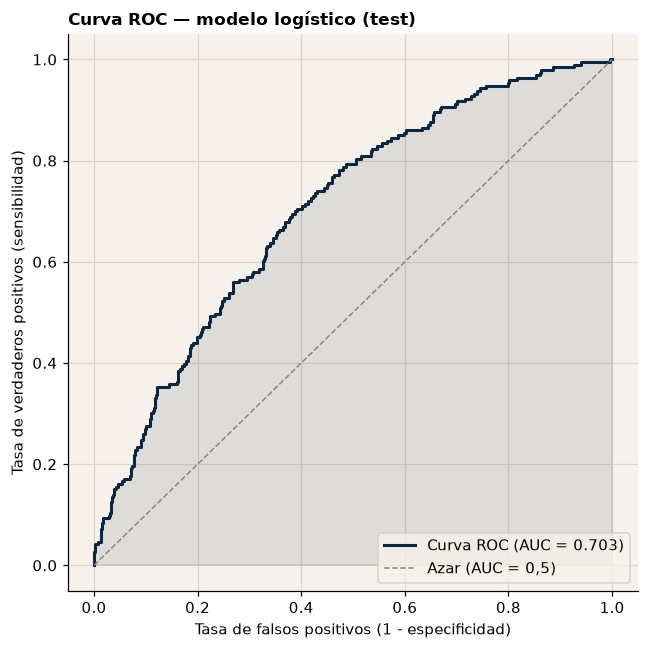

AUC = 0.703


In [8]:
FIGURAS = ROOT / "redaccion/formativa-2-modelamiento-predictivo/figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

y_prob = modelo.predict(X_test_const)
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(fpr, tpr, color=NAVY, lw=2, label=f"Curva ROC (AUC = {roc_auc:.3f})")
ax.fill_between(fpr, tpr, alpha=0.1, color=NAVY)
ax.plot([0, 1], [0, 1], color=GREY, lw=1, ls="--", label="Azar (AUC = 0,5)")
ax.set_xlabel("Tasa de falsos positivos (1 - especificidad)")
ax.set_ylabel("Tasa de verdaderos positivos (sensibilidad)")
ax.set_title("Curva ROC — modelo logístico (test)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIGURAS / "fig_roc.png", bbox_inches="tight")
plt.show()

print(f"AUC = {roc_auc:.3f}")

**Lectura.** El AUC en test es 0,703, dentro del rango "aceptable" (0,7-0,8) de la escala de referencia: el modelo discrimina mejor que el azar (AUC = 0,5) pero está lejos de un desempeño "bueno" (0,8-0,9) o "excelente" (>0,9). Esto es consistente con que las correlaciones individuales de S1 fueron modestas (máximo 0,225 en edad): cinco predictores con asociaciones moderadas producen un modelo con capacidad discriminativa moderada, no alta. El AUC evalúa el modelo en todos los umbrales posibles, a diferencia de las métricas de 3.1, que dependen del umbral fijo de 0,5; por eso ambas secciones se complementan: 3.1 muestra qué tan bien funciona ese umbral por defecto (probablemente con poco recall, dado el desbalance de clases) y 3.2 muestra el límite superior de desempeño del modelo, independiente del umbral elegido.

## 4. Síntesis y reflexión (15 pts, máx. 1 página)

**Cómo integramos S1 y S2.** No partimos de cero: usamos la misma copia versionada del dataset (SHA-256) que ya habíamos verificado en S1 y S2, para que los resultados fueran comparables entre evaluaciones. Elegimos las cinco variables (2.1) con el mismo criterio doble que validamos en S2: que la correlación apareciera en S1 y, cuando existía esa validación, que resistiera el bootstrap. También heredamos de S2 el tope de glucosa en 1.2, pensado justo para su cola extrema. Algo que nos llamó la atención: S2 había mostrado que fumador actual no se distingue de cero de forma marginal, pero en nuestro modelo multivariable cigarrillos por día sí resulta significativo (OR = 1,34) al controlar por las demás variables — su efecto parece depender de combinarse con la edad y la presión, no de actuar solo.

**Qué nos dice el desempeño.** Por dentro, el modelo nos convence: los cinco predictores son significativos (p ≤ 0,0008), sin multicolinealidad (VIF máx. 1,23) y con un AUC de 0,703 (aceptable), es decir, ordena razonablemente bien el riesgo relativo. Pero con el umbral de 0,5 el desempeño práctico nos decepciona: el recall es de solo 4,7 % y la accuracy (84,4 %) ni le gana al clasificador trivial (84,8 %). No lo vemos como una contradicción, sino como el síntoma esperado de evaluar un problema desbalanceado (prevalencia 15,2 %) con un umbral que nunca se pensó para esa prevalencia.

**Lo que nos proponemos mejorar en la Sumativa 3.**
1. Ponderar las clases o mover el umbral de decisión (en vez de 0,5 fijo), para mejorar el recall — crítico en este contexto de salud.
2. Aplicar bootstrap a los coeficientes/odds ratios (como en S2), para reportar IC en vez de solo el p-valor de MLE.
3. Comparar 2 o 3 modelos con distintos criterios de selección de variables (forward, backward, AIC/BIC).
4. Usar validación cruzada (k-fold) para elegir entre esos modelos candidatos, no un solo split train/test.
5. Imputar la glucosa (9,2 % de faltantes) por regresión en vez de mediana.

## Checklist de entrega
- [x] Ejecuta sin errores de principio a fin y con salidas visibles
- [x] Hallazgos de S1 y S2 documentados
- [x] Variables justificadas con S1/S2
- [x] Modelo, odds ratios y VIF
- [x] Matriz de confusión, métricas, ROC y AUC
- [x] Reflexión
- [x] Semilla fijada (SEED = 42)